# XSTAR run output viewer

A simple, path-driven notebook for exploring **the raw outputs of one XSTAR run**.

1. Set `path_to_xstar` in Section 1.
2. Run the notebook from top to bottom.
3. Use the tables, plots, and FITS browser to inspect the outputs that exist in that run directory.

The notebook discovers the standard XSTAR products automatically, checks every FITS extension, and also exposes additional FITS/log files so that version-specific outputs are not silently ignored. It requires `numpy`, `pandas`, `matplotlib`, `astropy`, and `ipywidgets` in the active Jupyter environment.

### Outputs covered

| Output | What you can inspect |
|---|---|
| `xout_spect1.fits` | Incident, transmitted, inward-emitted, and outward-emitted spectrum (with lines binned into the continuum) |
| `xout_cont1.fits` | The corresponding continuum-only spectrum |
| `xout_lines1.fits` | Strong emission-line list, wavelengths, luminosities, and optical depths |
| `xout_rrc1.fits` | Radiative recombination continua (RRCs) |
| `xout_abund1.fits` | Zone-by-zone ion fractions, ionic columns, heating, and cooling |
| `xout_step.log` | Run parameters, radial/thermal diagnostics, strongest lines/RRCs, and energy budget |
| `xoNN_detail*.fits` / `xoNN_detal*.fits` | Optional detailed level-population, line, RRC, and continuum information by spatial zone (`lwrite=1`) |

The detailed `xoNN_...fits` products can be large. They are inventoried automatically but are read only when selected in the interactive FITS browser.

**Documentation:** [XSTAR Manual, Release 2.5x (PDF)](https://heasarc.gsfc.nasa.gov/docs/software/xstar/docs/xstarmanual.pdf)


## 1. Imports and run configuration

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
import astropy.units as u
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": False, "grid.alpha": 0.25, "font.size": 10})

In [2]:
# Edit this path to the directory containing the raw products of ONE XSTAR run
path_to_xstar = Path("/data-fast/dragon/vicente/iongrid/runs/run_20261105_htc_lhs/points/p000000001").expanduser()

# Usually all files are directly inside path_to_xstar. Set True only if your run wrapper places outputs in nested subdirectories:
SEARCH_SUBDIRECTORIES = False

# Display choices (these affect presentation only; the FITS data are unchanged):
PLOT_ENERGY_UNIT = "keV"       
TABLE_PREVIEW_ROWS = 20
LOG_PREVIEW_CHARS = None       # None = display complete log files

## 2. Discover the files produced by this run

The standard files are expected in the run directory. The notebook also detects any other FITS and log files and keeps them available in the general inspector.

In [3]:
if not path_to_xstar.is_dir():
    raise FileNotFoundError(
        f"XSTAR run directory does not exist: {path_to_xstar}. Edit path_to_xstar in Section 1 and run the notebook again.")

EXPECTED_PRODUCTS = {
    "xout_spect1.fits": "Spectrum including line emission binned into the continuum",
    "xout_cont1.fits": "Continuum-only spectrum (without lines binned into it)",
    "xout_lines1.fits": "Strong emission-line list",
    "xout_abund1.fits": "Zone-by-zone ion fractions, ionic columns, heating, and cooling",
    "xout_rrc1.fits": "Radiative recombination continuum (RRC) list",
    "xout_step.log": "XSTAR run log and diagnostics",
}

def _product_description(filename):
    name = filename.lower()
    if name in EXPECTED_PRODUCTS:
        return EXPECTED_PRODUCTS[name]
    if re.match(r"^xo\d{2}_(?:detail|detal)\d*\.fits$", name):
        if "detail2" in name or "detal2" in name:
            return "Optional detailed line emissivities/opacity by zone (lwrite=1)"
        if "detail3" in name or "detal3" in name:
            return "Optional detailed RRC emissivities/opacity by zone (lwrite=1)"
        if "detail4" in name or "detal4" in name:
            return "Optional detailed continuum spectra/emissivities by zone (lwrite=1)"
        return "Optional detailed ionic level populations by zone (lwrite=1)"
    if name.endswith((".fits", ".fit", ".fts")):
        return "Additional FITS product (available in the general FITS browser)"
    if name.endswith((".log", ".out")):
        return "Additional text/log output"
    return "Other file in the run directory"

all_paths = sorted((p for p in (path_to_xstar.rglob("*") if SEARCH_SUBDIRECTORIES else path_to_xstar.iterdir()) if p.is_file()), key=lambda p: str(p).lower())
fits_paths = [p for p in all_paths if p.suffix.lower() in {".fits", ".fit", ".fts"}]
log_paths = [p for p in all_paths if p.suffix.lower() in {".log", ".out"}]

file_inventory = pd.DataFrame([
    {
        "file": str(p.relative_to(path_to_xstar)),
        "type": p.suffix.lower() or "(no extension)",
        "size [MiB]": round(p.stat().st_size / 1024**2, 3),
        "description": _product_description(p.name),
    }
    for p in all_paths
])

print(f"Run directory: {path_to_xstar.resolve()}")
print(f"Files found: {len(all_paths)} | FITS files: {len(fits_paths)} | log/output files: {len(log_paths)}")
display(file_inventory if not file_inventory.empty else pd.DataFrame({"message": ["No files found in this directory."]}))

# Map standard products to their discovered paths (also works when SEARCH_SUBDIRECTORIES=True):
standard_paths = {
    name: next((p for p in all_paths if p.name.lower() == name.lower()), path_to_xstar / name)
    for name in EXPECTED_PRODUCTS
}
found_basenames = {p.name.lower() for p in all_paths}
missing_standard = [name for name in EXPECTED_PRODUCTS if name.lower() not in found_basenames]
if missing_standard:
    print("\nStandard products not found (this is not necessarily an error):")
    for name in missing_standard:
        print(f"  - {name}")

if not fits_paths:
    print("\nNo FITS files were found. Check the run directory or SEARCH_SUBDIRECTORIES setting.")


Run directory: /data-fast/dragon/vicente/iongrid/runs/run_20261105_htc_lhs/points/p000000001
Files found: 15 | FITS files: 5 | log/output files: 2


,file,type,size [MiB],description
0,.lock,(no extension),0.000,Other file in the run directory
1,collect.json,.json,0.000,Other file in the run directory
2,inputs.json,.json,0.000,Other file in the run directory
3,overrides.json,.json,0.000,Other file in the run directory
4,p000000001.npz,.npz,0.218,Other file in the run directory
5,run.json,.json,0.000,Other file in the run directory
6,stderr.log,.log,0.000,Additional text/log output
7,xout_abund1.fits,.fits,0.286,"Zone-by-zone ion fractions, ionic columns, heating, and cooling"
8,xout_cont1.fits,.fits,0.673,Continuum-only spectrum (without lines binned into it)
9,xout_lines1.fits,.fits,0.091,Strong emission-line list


## 3. Inspect all FITS extensions (HDUs)

This inventory reads the FITS structure and column definitions without copying every table into memory. It is especially useful for the optional per-zone files, which can be large.

In [4]:
def inventory_fits_file(filepath):
    rows = []
    with fits.open(filepath, memmap=False, lazy_load_hdus=True) as hdul:
        for hdu_index, hdu in enumerate(hdul):
            is_table = isinstance(hdu, (fits.BinTableHDU, fits.TableHDU))
            columns = list(hdu.columns.names or []) if is_table else []
            rows.append({
                "file": str(filepath.relative_to(path_to_xstar)),
                "HDU": hdu_index,
                "class": type(hdu).__name__,
                "EXTNAME": hdu.header.get("EXTNAME", "(primary / unnamed)"),
                "rows": hdu.header.get("NAXIS2") if is_table else None,
                "columns": ", ".join(columns),
            })
    return rows

inventory_rows = []
for filepath in fits_paths:
    try:
        inventory_rows.extend(inventory_fits_file(filepath))
    except Exception as exc:
        inventory_rows.append({
            "file": str(filepath.relative_to(path_to_xstar)),
            "HDU": None,
            "class": "READ ERROR",
            "EXTNAME": "",
            "rows": None,
            "columns": str(exc),
        })

hdu_inventory = pd.DataFrame(inventory_rows)
display(hdu_inventory if not hdu_inventory.empty else pd.DataFrame({"message": ["No FITS HDUs to inspect."]}))


,file,HDU,class,EXTNAME,rows,columns
0,xout_abund1.fits,0,PrimaryHDU,(primary / unnamed),NaN,
1,xout_abund1.fits,1,TableHDU,ABUNDANCES,4.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, h_i, he_i, he_..."
2,xout_abund1.fits,2,TableHDU,COLUMNS,1.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, h_i, he_i, he_..."
3,xout_abund1.fits,3,TableHDU,HEATING,4.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, hydrogen, heli..."
4,xout_abund1.fits,4,TableHDU,COOLING,4.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, hydrogen, heli..."
5,xout_cont1.fits,0,PrimaryHDU,(primary / unnamed),NaN,
6,xout_cont1.fits,1,BinTableHDU,PARAMETERS,56.0,"index, parameter, value, type, comment"
7,xout_cont1.fits,2,TableHDU,XSTAR_SPECTRA,9999.0,"energy, incident, transmitted, emit_inward, emit_outward"
8,xout_lines1.fits,0,PrimaryHDU,(primary / unnamed),NaN,
9,xout_lines1.fits,1,BinTableHDU,PARAMETERS,56.0,"index, parameter, value, type, comment"


## 4. Read the run parameters

The standard XSTAR FITS products usually contain a `PARAMETERS` extension listing the input parameters. This cell uses the first such extension it finds.

In [5]:
def _read_table(filepath, hdu_index):
    """Read one FITS table HDU into a DataFrame; vector columns remain as array-valued cells."""
    with fits.open(filepath, memmap=False) as hdul:
        hdu = hdul[hdu_index]
        if not isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)) or hdu.data is None:
            raise TypeError(f"HDU {hdu_index} in {filepath.name} is not a populated table.")
        names = list(hdu.columns.names or [])
        data = {}
        for name in names:
            arr = np.asarray(hdu.data[name])
            data[name] = arr if arr.ndim <= 1 else list(arr)
        frame = pd.DataFrame(data)
        units = {col.name: col.unit for col in hdu.columns}
        header = hdu.header.copy()
    return frame, units, header


def _find_hdu_index(filepath, extname=None, required_columns=None):
    required_columns = [str(x).lower() for x in (required_columns or [])]
    with fits.open(filepath, memmap=False, lazy_load_hdus=True) as hdul:
        for i, hdu in enumerate(hdul):
            if not isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)):
                continue
            name = str(hdu.header.get("EXTNAME", "")).strip().lower()
            if extname is not None and name != extname.lower():
                continue
            names = [str(x).lower() for x in (hdu.columns.names or [])]
            if all(col in names for col in required_columns):
                return i
    return None


parameter_result = None
for filepath in fits_paths:
    idx = _find_hdu_index(filepath, extname="PARAMETERS")
    if idx is not None:
        parameter_result = (filepath, idx)
        break

if parameter_result is None:
    print("No PARAMETERS extension was found in the discovered FITS files.")
else:
    parameter_file, parameter_hdu = parameter_result
    parameter_table, parameter_units, _ = _read_table(parameter_file, parameter_hdu)
    print(f"Parameters read from: {parameter_file.name} (HDU {parameter_hdu})")
    display(parameter_table)


Parameters read from: xout_cont1.fits (HDU 1)


,index,parameter,value,type,comment
0,1,cfrac,1.000000e+00,real,
1,2,temperature,4.000000e+02,real,Units of 10**4 K
2,3,lcpres,0.000000e+00,integer,"1=yes, 0=no"
3,4,pressure,3.000000e-02,real,dynes/cm**2
4,5,density,1.000000e+12,real,cm**(-3)
5,6,spectrum,0.000000e+00,string,pow
6,7,spectrum_file,0.000000e+00,string,
7,8,spectun,0.000000e+00,integer,"0=energy, 1=photons"
8,9,trad,-1.432662e+00,real,or alpha
9,10,rlrad38,1.000000e+09,real,/10**38 erg/sec


## 5. Plot the spectral outputs

`xout_spect1.fits` contains the spectrum with lines binned into the continuum; `xout_cont1.fits` contains the continuum without those line contributions. The XSTAR documentation gives the energy column in **eV** and the specific-luminosity columns in units of `10^38 erg s^-1 erg^-1`.

The plot below converts the horizontal axis to `PLOT_ENERGY_UNIT` for display only. FITS values are not modified. It plots whichever of `incident`, `transmitted`, `emit_inward`, and `emit_outward` are present.

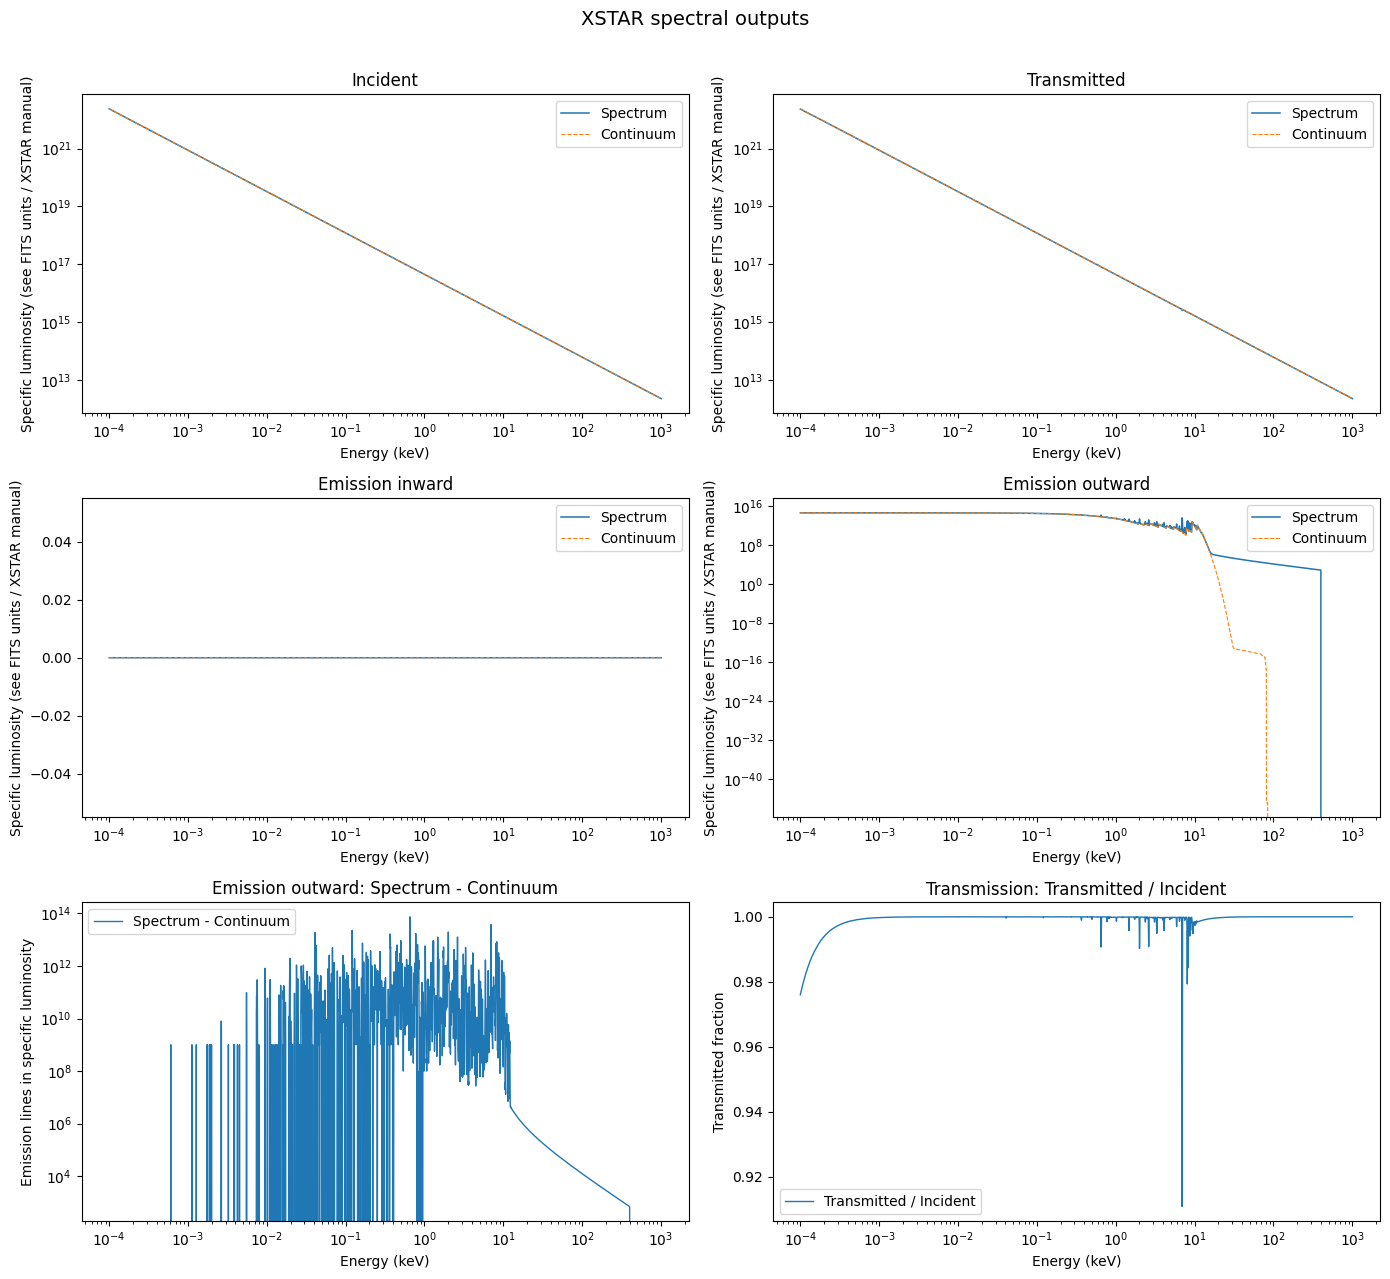

In [15]:
def _normalise_name(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).strip().lower())

def _matching_column(columns, candidates):
    normalised = {_normalise_name(c): c for c in columns}
    for candidate in candidates:
        key = _normalise_name(candidate)
        if key in normalised:
            return normalised[key]
    return None

def _scalar_numeric_columns(frame):
    result = []
    for col in frame.columns:
        arr = np.asarray(frame[col])
        if arr.ndim == 1 and arr.dtype.kind in "biufc":
            result.append(col)
    return result

def _energy_axis_values(values, unit, filepath):
    """Convert energy to PLOT_ENERGY_UNIT; standard xout spectra use eV per the manual."""
    values = np.asarray(values, dtype=float)
    source_unit = unit
    if source_unit in (None, ""):
        # The manual specifies eV for xout_spect1.fits and xout_cont1.fits.
        source_unit = "eV" if filepath.name.lower() in {"xout_spect1.fits", "xout_cont1.fits"} else None
    if source_unit is None:
        return values, "energy (FITS unit not specified; values unconverted)"
    try:
        converted = (values * u.Unit(source_unit)).to_value(u.Unit(PLOT_ENERGY_UNIT))
        return converted, f"Energy ({PLOT_ENERGY_UNIT})"
    except Exception:
        warnings.warn(f"Could not convert energy unit {source_unit!r}; plotting raw values.")
        return values, f"Energy ({source_unit}; unconverted)"

SPECTRAL_COLUMNS = [
    ("Incident", ["incident"]),
    ("Transmitted", ["transmitted"]),
    ("Emission inward", ["emit_inward", "emitinward"]),
    ("Emission outward", ["emit_outward", "emitoutward"]),
]

def plot_spectral_outputs(spectrum_filepath, continuum_filepath):
    # 1. Read spectrum file:
    spectrum_idx = _find_hdu_index(spectrum_filepath, extname="XSTAR_SPECTRA", required_columns=["energy"])
    if spectrum_idx is None:
        spectrum_idx = _find_hdu_index(spectrum_filepath, required_columns=["energy"])
    if spectrum_idx is None:
        print(f"No spectral table found in {spectrum_filepath.name}.")
        return
    spectrum_frame, spectrum_units, _ = _read_table(spectrum_filepath, spectrum_idx)
    # 2. Read continuum file:
    continuum_idx = _find_hdu_index(continuum_filepath, extname="XSTAR_SPECTRA", required_columns=["energy"])
    if continuum_idx is None:
        continuum_idx = _find_hdu_index(continuum_filepath, required_columns=["energy"])
    if continuum_idx is None:
        print(f"No spectral table found in {continuum_filepath.name}.")
        return
    continuum_frame, continuum_units, _ = _read_table(continuum_filepath, continuum_idx)
    # 3. Read energy grids:
    spectrum_energy_col = _matching_column(spectrum_frame.columns, ["energy"])
    continuum_energy_col = _matching_column(continuum_frame.columns, ["energy"])
    spectrum_energy = np.asarray(spectrum_frame[spectrum_energy_col], dtype=float).squeeze()
    continuum_energy = np.asarray(continuum_frame[continuum_energy_col], dtype=float).squeeze()
    spectrum_energy, energy_label = _energy_axis_values(spectrum_energy,spectrum_units.get(spectrum_energy_col),spectrum_filepath)
    continuum_energy, _ = _energy_axis_values(continuum_energy,continuum_units.get(continuum_energy_col),continuum_filepath)
    # 4. Helper functions:
    def get_column(frame, candidates):
        col = _matching_column(frame.columns, candidates)
        if col is None:
            return None
        values = np.asarray(frame[col], dtype=float).squeeze()
        if values.ndim != 1:
            return None
        return values
    def interpolate_to_spectrum_grid(energy, values):
        """
        Interpolate continuum values onto the spectrum energy grid.
        Values outside the continuum energy range are set to NaN.
        """
        valid = (np.isfinite(energy) & np.isfinite(values) & (energy > 0))
        if valid.sum() < 2:
            return np.full(spectrum_energy.shape, np.nan)
        x = energy[valid]
        y = values[valid]
        order = np.argsort(x)
        x = x[order]
        y = y[order]
        return np.interp(
            spectrum_energy,
            x,
            y,
            left=np.nan,
            right=np.nan,
        )
    # 5. Extract spectral components:
    components = [
        ("Incident", ["incident"]),
        ("Transmitted", ["transmitted"]),
        ("Emission inward", ["emit_inward", "emitinward"]),
        ("Emission outward", ["emit_outward", "emitoutward"]),
    ]
    spectra = {}
    continua = {}
    for label, candidates in components:
        spectra[label] = get_column(spectrum_frame, candidates)
        continua[label] = get_column(continuum_frame, candidates)
    # 6. Create six panels:
    fig, axes = plt.subplots(3, 2,figsize=(14, 13))
    axes = axes.ravel()
    # First four panels: spectrum and continuum:
    for i, (label, _) in enumerate(components):
        ax = axes[i]
        spectrum = spectra[label]
        continuum = continua[label]
        # Spectrum: first default colour, solid:
        if spectrum is not None and spectrum.size == spectrum_energy.size:
            mask = (np.isfinite(spectrum_energy) & np.isfinite(spectrum) & (spectrum_energy > 0))
            if mask.any():
                ax.plot(
                    spectrum_energy[mask],
                    spectrum[mask],
                    color="C0",
                    linestyle="-",
                    linewidth=1.1,
                    label="Spectrum",
                )
        # Continuum: second default colour, dashed:
        if continuum is not None and continuum.size == continuum_energy.size:
            mask = (np.isfinite(continuum_energy) & np.isfinite(continuum) & (continuum_energy > 0))
            if mask.any():
                ax.plot(
                    continuum_energy[mask],
                    continuum[mask],
                    color="C1",
                    linestyle="--",
                    linewidth=0.8,
                    label="Continuum",
                )
        ax.set_title(label)
        ax.set_xscale("log")
        plotted_values = []
        if spectrum is not None and spectrum.size == spectrum_energy.size:
            plotted_values.extend(spectrum[np.isfinite(spectrum) & (spectrum > 0)])
        if continuum is not None and continuum.size == continuum_energy.size:
            plotted_values.extend(continuum[np.isfinite(continuum) & (continuum > 0)])
        if len(plotted_values) and np.all(np.asarray(plotted_values) > 0):
            ax.set_yscale("log")
        ax.set_xlabel(energy_label)
        ax.set_ylabel("Specific luminosity (see FITS units / XSTAR manual)")
        ax.legend()
        ax.grid(False)
    # 7. Fifth panel: Emission outward - Continuum outward:
    ax = axes[4]
    outward_spectrum = spectra["Emission outward"]
    outward_continuum = continua["Emission outward"]
    if (
        outward_spectrum is not None
        and outward_continuum is not None
        and outward_spectrum.size == spectrum_energy.size
        and outward_continuum.size == continuum_energy.size
    ):
        difference = outward_spectrum - outward_continuum
        mask = (np.isfinite(spectrum_energy) & np.isfinite(difference) & (spectrum_energy > 0))
        ax.plot(
            spectrum_energy[mask],
            difference[mask],
            color="C0",
            linewidth=1.0,
            label="Spectrum - Continuum",
        )
        ax.legend()
    else:
        ax.text(
            0.5, 0.5,
            "Required emission outward columns unavailable",
            ha="center", va="center",
            transform=ax.transAxes,
        )
    ax.set_title("Emission outward: Spectrum - Continuum")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(energy_label)
    ax.set_ylabel("Emission lines in specific luminosity")
    ax.grid(False)
    # 8. Sixth panel: Transmitted / Incident:
    ax = axes[5]
    incident = spectra["Incident"]
    transmitted = spectra["Transmitted"]

    if (
        incident is not None
        and transmitted is not None
        and incident.size == spectrum_energy.size
        and transmitted.size == spectrum_energy.size
    ):
        ratio = np.full(spectrum_energy.shape, np.nan)
        valid = (
            np.isfinite(incident)
            & np.isfinite(transmitted)
            & np.isfinite(spectrum_energy)
            & (spectrum_energy > 0)
            & (incident != 0)
        )
        ratio[valid] = transmitted[valid] / incident[valid]
        mask = np.isfinite(ratio)
        ax.plot(
            spectrum_energy[mask],
            ratio[mask],
            color="C0",
            linewidth=1.0,
            label="Transmitted / Incident",
        )
        ax.legend()
    else:
        ax.text(
            0.5, 0.5,
            "Required incident/transmitted columns unavailable",
            ha="center", va="center",
            transform=ax.transAxes,
        )
    ax.set_title("Transmission: Transmitted / Incident")
    ax.set_xscale("log")
    ax.set_xlabel(energy_label)
    ax.set_ylabel("Transmitted fraction")
    ax.grid(False)
    # 9. Overall figure formatting:
    fig.suptitle("XSTAR spectral outputs", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

# Plot all six panels:
spectrum_filepath = standard_paths["xout_spect1.fits"]
continuum_filepath = standard_paths["xout_cont1.fits"]
if spectrum_filepath.is_file() and continuum_filepath.is_file():
    plot_spectral_outputs(spectrum_filepath, continuum_filepath)
else:
    print("Both xout_spect1.fits and xout_cont1.fits are required.")

## 6. Inspect and plot the line and RRC lists

The line and RRC files are **transition lists**, not spectra sampled on the continuum energy grid. Their x-axes therefore use wavelength (line list) or transition energy (RRC list). Use the dropdown to choose which numeric quantity to plot.

In [7]:
def show_transition_output(filename, extname, x_candidates, title, x_label, preferred_y_candidates):
    filepath = standard_paths.get(filename, path_to_xstar / filename)
    if not filepath.is_file():
        print(f"{filename} not found; skipping this section.")
        return

    idx = _find_hdu_index(filepath, extname=extname)
    if idx is None:
        idx = _find_hdu_index(filepath)
    if idx is None:
        print(f"No table HDU found in {filename}.")
        return

    frame, units, _ = _read_table(filepath, idx)
    x_col = _matching_column(frame.columns, x_candidates)
    if x_col is None:
        print(f"Could not identify the x-axis column in {filename}. Available columns: {list(frame.columns)}")
        display(frame.head(TABLE_PREVIEW_ROWS))
        return

    print(f"{filename}: {len(frame):,} row(s); preview:")
    display(frame.head(TABLE_PREVIEW_ROWS))

    numeric = _scalar_numeric_columns(frame)
    y_options = [col for col in numeric if col != x_col]
    if not y_options:
        print("No scalar numeric columns are available for plotting.")
        return
    default_y = _matching_column(y_options, preferred_y_candidates) or y_options[0]
    max_n = max(1, len(frame))

    def _plot(y_column=default_y, number_to_plot=max_n):
        x = np.asarray(frame[x_col], dtype=float)
        y = np.asarray(frame[y_column], dtype=float)
        mask = np.isfinite(x) & np.isfinite(y)
        if mask.sum() == 0:
            print("No finite values to plot.")
            return
        x, y = x[mask], y[mask]
        if number_to_plot < x.size:
            keep = np.argsort(np.abs(y))[-number_to_plot:]
            x, y = x[keep], y[keep]
        order = np.argsort(x)
        x, y = x[order], y[order]

        fig, ax = plt.subplots(figsize=(10, 4.8))
        ax.scatter(x, y, s=16, alpha=0.8)
        if np.all(x > 0):
            ax.set_xscale("log")
        if np.all(y > 0):
            ax.set_yscale("log")
        x_unit = units.get(x_col)
        y_unit = units.get(y_column)
        ax.set_xlabel(f"{x_label} [{x_unit}]" if x_unit else x_label)
        ax.set_ylabel(f"{y_column} [{y_unit}]" if y_unit else y_column)
        ax.set_title(f"{title}: {y_column}")
        fig.tight_layout()
        plt.show()

    controls = widgets.interactive(
        _plot,
        y_column=widgets.Dropdown(options=y_options, value=default_y, description="Y column:"),
        number_to_plot=widgets.IntSlider(
            value=max_n, min=1, max=max_n, step=max(1, max_n // 100),
            description="Points:", continuous_update=False,
            style={"description_width": "initial"},
        ),
    )
    display(controls)


show_transition_output(
    "xout_lines1.fits", "XSTAR_LINES", ["wavelength"],
    "XSTAR emission-line list", "Wavelength", ["emit_outward", "emit_inward"],
)

show_transition_output(
    "xout_rrc1.fits", "XSTAR_SPECTRA", ["energy"],
    "XSTAR radiative recombination continua", "Transition energy", ["emit_outward", "emit_inward"],
)


xout_lines1.fits: 600 row(s); preview:


,index,ion,lower_level,upper_level,wavelength,emit_inward,emit_outward,depth_inward,depth_outward
0,398545,fe_xxvi,1s1.2S_1/2,1s0.2p1.2P_3/2,1.77802,0.0,2039.7600,0.187417,0.0
1,398544,fe_xxvi,1s1.2S_1/2,1s0.2p1.2P_1/2,1.78344,0.0,1607.7600,0.094569,0.0
2,398541,fe_xxvi,1s1.2S_1/2,1s0.3p1.2P_3/2,1.50235,0.0,498.9730,0.030184,0.0
3,573337,ni_xxviii,1s1.2S_1/2,1s0.2p1.2P_3/2,1.53034,0.0,460.4420,0.041941,0.0
4,573336,ni_xxviii,1s1.2S_1/2,1s0.2p1.2P_1/2,1.53577,0.0,369.6060,0.021195,0.0
5,7765,o_viii,1s1.2S_1/2,1s0.2p1.2P_3/2,18.96710,0.0,338.7700,0.018046,0.0
6,398540,fe_xxvi,1s1.2S_1/2,1s0.3p1.2P_1/2,1.50350,0.0,337.4020,0.015126,0.0
7,27764,si_xiv,1s1.2S_1/2,1s0.2p1.2P_3/2,6.18042,0.0,269.0090,0.018744,0.0
8,36699,s_xvi,1s1.2S_1/2,1s0.2p1.2P_3/2,4.72735,0.0,236.2480,0.017773,0.0
9,7764,o_viii,1s1.2S_1/2,1s0.2p1.2P_1/2,18.97250,0.0,231.1770,0.009031,0.0


interactive(children=(Dropdown(description='Y column:', index=2, options=('index', 'emit_inward', 'emit_outwar…

xout_rrc1.fits: 2,482 row(s); preview:


,index,ion,level,energy,emit_outward,emit_inward,depth_outward,depth_inward
0,1,h_i,1s0.6f1.2F,0.377700,0.005010,0.005010,0.0,0.0
1,2,h_i,1s0.5f1.2F_7/2,0.545493,0.004338,0.004338,0.0,0.0
2,3,h_i,1s0.5f1.2F_5/2,0.545494,0.003253,0.003253,0.0,0.0
3,4,h_i,1s0.6h1.2H,0.377700,0.000221,0.000221,0.0,0.0
4,5,h_i,1s0.6g1.2G,0.377700,0.001238,0.001238,0.0,0.0
5,6,h_i,1s0.5s1.2S_1/2,0.545497,2.453890,2.453890,0.0,0.0
6,7,h_i,1s0.2p1.2P_1/2,3.401190,1.556570,1.556570,0.0,0.0
7,8,h_i,1s0.2p1.2P_3/2,3.401270,3.113190,3.113190,0.0,0.0
8,9,h_i,1s0.6p1.2P,0.377700,0.161855,0.161855,0.0,0.0
9,10,h_i,1s0.6s1.2S,0.377700,1.275990,1.275990,0.0,0.0


interactive(children=(Dropdown(description='Y column:', index=1, options=('index', 'emit_outward', 'emit_inwar…

## 7. Explore the ion fractions, ionic columns, heating, and cooling

`xout_abund1.fits` normally contains the extensions `ABUNDANCES`, `COLUMNS`, `HEATING`, and `COOLING`.

- `ABUNDANCES`: ion fractions and local physical conditions as a function of depth/zone.
- `COLUMNS`: ionic column densities.
- `HEATING` and `COOLING`: heating/cooling-rate information.

For the first two tables, select any numeric column to plot against radius (or another numeric x-axis). This also lets you select individual ion columns, whose names depend on the elements/ions present in the calculation.

In [8]:
def show_abundance_extension(extname, default_y_candidates=()):
    filepath = standard_paths["xout_abund1.fits"]
    if not filepath.is_file():
        return
    idx = _find_hdu_index(filepath, extname=extname)
    if idx is None:
        print(f"Extension {extname!r} not found in xout_abund1.fits.")
        return

    frame, units, _ = _read_table(filepath, idx)
    print(f"{extname}: {len(frame):,} row(s), {len(frame.columns)} column(s); preview:")
    display(frame.head(TABLE_PREVIEW_ROWS))

    numeric = _scalar_numeric_columns(frame)
    if not numeric:
        print("No scalar numeric columns found in this extension.")
        return

    x_default = _matching_column(numeric, ["radius"]) or numeric[0]
    y_options = [col for col in numeric if col != x_default]
    if not y_options:
        return
    y_default = _matching_column(y_options, list(default_y_candidates)) or y_options[0]

    def _plot(x_column=x_default, y_column=y_default, x_scale="log", y_scale="log"):
        x = np.asarray(frame[x_column], dtype=float)
        y = np.asarray(frame[y_column], dtype=float)
        mask = np.isfinite(x) & np.isfinite(y)
        if x_scale == "log":
            mask &= x > 0
        if y_scale == "log":
            mask &= y > 0
        if mask.sum() == 0:
            print("No finite points satisfy the selected axis scales.")
            return
        order = np.argsort(x[mask])
        x_plot = x[mask][order]
        y_plot = y[mask][order]
        fig, ax = plt.subplots(figsize=(10, 4.8))
        ax.plot(x_plot, y_plot, marker=".", ms=4, lw=1)
        ax.set_xscale(x_scale)
        ax.set_yscale(y_scale)
        x_unit = units.get(x_column)
        y_unit = units.get(y_column)
        ax.set_xlabel(f"{x_column} [{x_unit}]" if x_unit else x_column)
        ax.set_ylabel(f"{y_column} [{y_unit}]" if y_unit else y_column)
        ax.set_title(f"xout_abund1.fits — {extname}")
        fig.tight_layout()
        plt.show()

    controls = widgets.interactive(
        _plot,
        x_column=widgets.Dropdown(options=numeric, value=x_default, description="X column:"),
        y_column=widgets.Dropdown(options=y_options, value=y_default, description="Y column:"),
        x_scale=widgets.ToggleButtons(options=["linear", "log"], value="log", description="X scale:"),
        y_scale=widgets.ToggleButtons(options=["linear", "log"], value="log", description="Y scale:"),
    )
    display(controls)


if (path_to_xstar / "xout_abund1.fits").is_file():
    show_abundance_extension("ABUNDANCES", ["temperature", "ion_parameter", "x_e", "n_p"])
    show_abundance_extension("COLUMNS")
    show_abundance_extension("HEATING")
    show_abundance_extension("COOLING")
else:
    print("xout_abund1.fits not found.")


ABUNDANCES: 4 row(s), 473 column(s); preview:


,radius,delta_r,ion_parameter,x_e,n_p,pressure,temperature,frac_heat_error,h_i,he_i,he_ii,li_i,li_ii,li_iii,be_i,be_ii,be_iii,be_iv,b_i,b_ii,b_iii,b_iv,b_v,c_i,c_ii,c_iii,c_iv,c_v,c_vi,n_i,...,zn_i,zn_ii,zn_iii,zn_iv,zn_v,zn_vi,zn_vii,zn_viii,zn_ix,zn_x,zn_xi,zn_xii,zn_xiii,zn_xiv,zn_xv,zn_xvi,zn_xvii,zn_xviii,zn_xix,zn_xx,zn_xxi,zn_xxii,zn_xxiii,zn_xxiv,zn_xxv,zn_xxvi,zn_xxvii,zn_xxviii,zn_xxix,zn_xxx
0,8.625300e+13,0.000000e+00,7.12845,1.0,1.000000e+12,0.03,400.0,-0.170729,5.691820e-14,0.0,9.035520e-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.758510e-08,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000008,0.004455
1,8.625300e+13,0.000000e+00,7.12845,1.0,1.000000e+12,0.03,400.0,-0.170732,5.691820e-14,0.0,9.036890e-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.779010e-08,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000008,0.004456
2,9.082330e+13,4.570270e+12,7.08361,1.0,1.000000e+12,0.03,400.0,-0.173242,6.031930e-14,0.0,1.003570e-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.416950e-08,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000010,0.004942
3,0.000000e+00,0.000000e+00,0.00000,0.0,0.000000e+00,0.00,0.0,0.000000,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000


interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

COLUMNS: 1 row(s), 473 column(s); preview:


,radius,delta_r,ion_parameter,x_e,n_p,pressure,temperature,frac_heat_error,h_i,he_i,he_ii,li_i,li_ii,li_iii,be_i,be_ii,be_iii,be_iv,b_i,b_ii,b_iii,b_iv,b_v,c_i,c_ii,c_iii,c_iv,c_v,c_vi,n_i,...,zn_i,zn_ii,zn_iii,zn_iv,zn_v,zn_vi,zn_vii,zn_viii,zn_ix,zn_x,zn_xi,zn_xii,zn_xiii,zn_xiv,zn_xv,zn_xvi,zn_xvii,zn_xviii,zn_xix,zn_xx,zn_xxi,zn_xxii,zn_xxiii,zn_xxiv,zn_xxv,zn_xxvi,zn_xxvii,zn_xxviii,zn_xxix,zn_xxx
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.300660e+11,0.0,2.065050e+12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.886160e+13,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.883050e+11,1.608780e+14


interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

... (2 outputs left out)

interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

COOLING: 4 row(s), 41 column(s); preview:


,radius,delta_r,ion_parameter,x_e,n_p,pressure,temperature,frac_heat_error,hydrogen,helium,lithium,beryllium,boron,carbon,nitrogen,oxygen,fluorine,neon,sodium,magnesium,aluminum,silicon,phosphoru,sulfur,chlorine,argon,potassium,calcium,scandium,titanium,vanadium,chromium,manganese,iron,cobalt,nickel,copper,zinc,compton,brems,total
0,8.625300e+13,0.000000e+00,7.12845,1.0,1.000000e+12,0.03,400.0,-0.170729,6.16104,0.538210,0.0,0.0,0.0,0.143372,0.081005,0.880759,0.000138,0.090771,0.014301,0.251546,0.040000,0.487036,0.009983,0.405694,0.019831,0.196514,0.007453,0.140684,0.000213,0.021241,0.004577,0.154591,0.062748,2.54583,0.048028,0.519786,0.015861,0.008805,27147.4,3.9884,27164.3
1,8.625300e+13,0.000000e+00,7.12845,1.0,1.000000e+12,0.03,400.0,-0.170732,6.16104,0.538210,0.0,0.0,0.0,0.142714,0.080659,0.876602,0.000138,0.090743,0.014268,0.251688,0.039884,0.488011,0.009947,0.409301,0.019763,0.199963,0.007436,0.144543,0.000213,0.021229,0.004572,0.154477,0.062757,2.69042,0.048036,0.555535,0.015858,0.008808,27147.4,3.9884,27164.5
2,9.082330e+13,4.570270e+12,7.08361,1.0,1.000000e+12,0.03,400.0,-0.173242,5.52330,0.525961,0.0,0.0,0.0,0.142815,0.080685,0.876802,0.000138,0.090728,0.014281,0.251887,0.039922,0.488856,0.009959,0.410884,0.019785,0.200929,0.007440,0.145238,0.000213,0.021236,0.004573,0.154481,0.062760,2.69120,0.048034,0.555419,0.015859,0.008808,24418.5,3.9884,24434.9
3,0.000000e+00,0.000000e+00,0.00000,0.0,0.000000e+00,0.00,0.0,0.000000,0.00000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0000,0.0


interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

## 8. Read the XSTAR run log(s)

`xout_step.log` is always written by XSTAR. Its level of detail depends on `lprint`. The manual describes the zone-by-zone physical diagnostics, strongest line and RRC summaries, and the energy-budget information in this file.

In [9]:
if not log_paths:
    print("No .log or .out files were found.")
else:
    for log_path in log_paths:
        print("\n" + "=" * 100)
        print(log_path.relative_to(path_to_xstar))
        print("=" * 100)
        try:
            content = log_path.read_text(errors="replace")
            if LOG_PREVIEW_CHARS is not None and len(content) > LOG_PREVIEW_CHARS:
                print(content[:LOG_PREVIEW_CHARS])
                print(f"\n[Truncated after {LOG_PREVIEW_CHARS:,} characters; set LOG_PREVIEW_CHARS=None to display the complete file.]")
            else:
                print(content)
        except Exception as exc:
            print(f"Could not read {log_path.name}: {exc}")



stderr.log


xout_step.log
 xstar version 2.59g
 nry=        3170        9999
 xstar version 2.59g
 Loading Atomic Database...
 Atomic Data Version: 2025-03-19T16:30:54
 in readtbl:
 number of pointers=     1216792
 number of reals=   199199476
 number of integers=     6205274
 number of characters=      753844
 initializng database...
 number of lines=      736256
 number of rrcs=      301301
 done with setptrs
  
 print option: 3
 print option: 2

 input parameters:
covering fraction=      1.000E+00
temperature (/10**4K)=  4.000E+02
 constant pressure switch (1=yes, 0=no)=           0
pressure (dyne/cm**2)=  3.000E-02
density (cm**-3)=       1.000E+12
 spectrum type=pow     
 spectrum file=        
 spectrum units? (0=energy, 1=photons)           0
radiation temperature or alpha= -1.433E+00
luminosity (/10**38 erg/s)=  1.000E+09
column density (cm**-2  4.570E+24
log(ionization parameter)=  7.128E+00
flux=                   1.070E+18
 abundance table: xdef
 abundances:
 element,   re